In [4]:

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import pandas as pd

data = pd.read_csv("/content/drive/MyDrive/healthcare_dataset.csv")
print(data)

                    Name  Age  Gender Blood Type Medical Condition  \
0          Bobby JacksOn   30    Male         B-            Cancer   
1           LesLie TErRy   62    Male         A+           Obesity   
2            DaNnY sMitH   76  Female         A-           Obesity   
3           andrEw waTtS   28  Female         O+          Diabetes   
4          adrIENNE bEll   43  Female        AB+            Cancer   
...                  ...  ...     ...        ...               ...   
55495  eLIZABeTH jaCkSOn   42  Female         O+            Asthma   
55496         KYle pEREz   61  Female        AB-           Obesity   
55497       HEATher WaNG   38  Female         B+      Hypertension   
55498     JENniFER JOneS   43    Male         O-         Arthritis   
55499       jAMES GARCiA   53  Female         O+         Arthritis   

      Date of Admission            Doctor                      Hospital  \
0            2024-01-31     Matthew Smith               Sons and Miller   
1        

In [6]:
data.shape

(55500, 15)

In [7]:
data.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  object 
 12  Discharge Date      55500 non-null  object 
 13  Medication          55500 non-null  object 
 14  Test Results        55500 non-null  object 
dtypes: float64(1), int64(2), object(12)
memory usage: 6.4

In [9]:
data.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


In [10]:
data.duplicated().sum()

np.int64(534)

In [11]:
data = data.drop_duplicates()

In [12]:
print("Duplicates after cleaning:", data.duplicated().sum())
print("Dataset shape after cleaning:", data.shape)

Duplicates after cleaning: 0
Dataset shape after cleaning: (54966, 15)


In [13]:
data["Gender"].value_counts()
data["Medical Condition"].value_counts()
data["Admission Type"].value_counts()

,count
Admission Type,
Elective,18473
Urgent,18391
Emergency,18102


In [14]:
data["Date of Admission"] = pd.to_datetime(data["Date of Admission"])
data["Discharge Date"] = pd.to_datetime(data["Discharge Date"])

In [15]:
data["Length of Stay"] = (
    data["Discharge Date"] - data["Date of Admission"]
).dt.days

In [16]:
data.isnull().sum()

,0
Name,0
Age,0
Gender,0
Blood Type,0
Medical Condition,0
Date of Admission,0
Doctor,0
Hospital,0
Insurance Provider,0
Billing Amount,0


In [17]:
data.dtypes

,0
Name,object
Age,int64
Gender,object
Blood Type,object
Medical Condition,object
Date of Admission,datetime64[ns]
Doctor,object
Hospital,object
Insurance Provider,object
Billing Amount,float64


In [18]:
print("Gender:")
print(data["Gender"].value_counts())

print("\nBlood Type:")
print(data["Blood Type"].value_counts())

print("\nMedical Condition:")
print(data["Medical Condition"].value_counts())

print("\nAdmission Type:")
print(data["Admission Type"].value_counts())

print("\nMedication:")
print(data["Medication"].value_counts())

print("\nTest Results:")
print(data["Test Results"].value_counts())

Gender:
Gender
Male      27496
Female    27470
Name: count, dtype: int64

Blood Type:
Blood Type
A-     6898
A+     6896
B+     6885
AB+    6882
AB-    6874
B-     6872
O+     6855
O-     6804
Name: count, dtype: int64

Medical Condition:
Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

Admission Type:
Admission Type
Elective     18473
Urgent       18391
Emergency    18102
Name: count, dtype: int64

Medication:
Medication
Lipitor        11038
Ibuprofen      11023
Aspirin        10984
Paracetamol    10965
Penicillin     10956
Name: count, dtype: int64

Test Results:
Test Results
Abnormal        18437
Normal          18331
Inconclusive    18198
Name: count, dtype: int64


In [19]:
data[["Age", "Billing Amount", "Room Number"]].describe()

,Age,Billing Amount,Room Number
count,54966.000000,54966.000000,54966.000000
mean,51.535185,25544.306284,301.124404
std,19.605661,14208.409711,115.223143
min,13.000000,-2008.492140,101.000000
25%,35.000000,13243.718641,202.000000
50%,52.000000,25542.749145,302.000000
75%,68.000000,37819.858159,401.000000
max,89.000000,52764.276736,500.000000


In [20]:
data["Date of Admission"] = pd.to_datetime(data["Date of Admission"])
data["Discharge Date"] = pd.to_datetime(data["Discharge Date"])

In [21]:
print(data["Date of Admission"].min())
print(data["Date of Admission"].max())

print(data["Discharge Date"].min())
print(data["Discharge Date"].max())

2019-05-08 00:00:00
2024-05-07 00:00:00
2019-05-09 00:00:00
2024-06-06 00:00:00


In [22]:
data["Length of Stay"] = (
    data["Discharge Date"] - data["Date of Admission"]
).dt.days

In [23]:
data["Length of Stay"].describe()

,Length of Stay
count,54966.000000
mean,15.499290
std,8.661471
min,1.000000
25%,8.000000
50%,15.000000
75%,23.000000
max,30.000000


In [24]:
data["Length of Stay"].value_counts().sort_index().head(20)

,count
Length of Stay,
1,1808
2,1830
3,1828
4,1848
5,1819
6,1889
7,1864
8,1807
9,1856


In [25]:
data[["Age", "Billing Amount", "Room Number", "Length of Stay"]].describe()

,Age,Billing Amount,Room Number,Length of Stay
count,54966.000000,54966.000000,54966.000000,54966.000000
mean,51.535185,25544.306284,301.124404,15.499290
std,19.605661,14208.409711,115.223143,8.661471
min,13.000000,-2008.492140,101.000000,1.000000
25%,35.000000,13243.718641,202.000000,8.000000
50%,52.000000,25542.749145,302.000000,15.000000
75%,68.000000,37819.858159,401.000000,23.000000
max,89.000000,52764.276736,500.000000,30.000000


In [26]:
negative_bills = data[data["Billing Amount"] < 0]

print("Negative billing records:", len(negative_bills))
negative_bills

Negative billing records: 106


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length of Stay
132,ashLEy ERIcKSoN,32,Female,AB-,Cancer,2019-11-05,Gerald Hooper,"and Johnson Moore, Branch",Aetna,-502.507813,376,Urgent,2019-11-23,Penicillin,Normal,18
799,CHRisTOPHer wEiss,49,Female,AB-,Asthma,2023-02-16,Kelly Thompson,Hunter-Hughes,Aetna,-1018.245371,204,Elective,2023-03-09,Penicillin,Inconclusive,21
1018,AsHley WaRnER,60,Male,A+,Hypertension,2021-12-21,Andrea Bentley,"and Wagner, Lee Klein",Aetna,-306.364925,426,Elective,2022-01-11,Ibuprofen,Normal,21
1421,JAY galloWaY,74,Female,O+,Asthma,2021-01-20,Debra Everett,Group Peters,Blue Cross,-109.097122,381,Emergency,2021-02-09,Ibuprofen,Abnormal,20
2103,josHUa wilLIamSon,72,Female,B-,Diabetes,2021-03-21,Wendy Ramos,"and Huff Reeves, Dennis",Blue Cross,-576.727907,369,Urgent,2021-04-17,Aspirin,Abnormal,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52213,mr. ChRIStOPhER aLvARaDO,74,Male,AB+,Obesity,2022-06-03,Mr. Dean Guzman DDS,Johnson Inc,Blue Cross,-1310.272895,257,Elective,2022-06-13,Paracetamol,Inconclusive,10
52629,gABrieLlE deCkER,66,Male,AB-,Arthritis,2022-11-07,William Krause,Diaz-Bishop,Cigna,-676.852502,354,Urgent,2022-11-30,Penicillin,Normal,23
53204,AsHley WaRnER,55,Male,A+,Hypertension,2021-12-21,Andrea Bentley,"and Wagner, Lee Klein",Aetna,-306.364925,426,Elective,2022-01-11,Ibuprofen,Normal,21
53232,dAnIel dRaKe,68,Female,B+,Hypertension,2020-04-24,Brett Ray,Carr Ltd,Aetna,-591.917419,426,Elective,2020-04-26,Lipitor,Abnormal,2


In [27]:
data = data[data["Billing Amount"] >= 0]

In [28]:
print("Negative billing records after cleaning:",
      (data["Billing Amount"] < 0).sum())

print("Dataset shape after cleaning:", data.shape)

Negative billing records after cleaning: 0
Dataset shape after cleaning: (54860, 16)


In [29]:
Q1 = data[["Age", "Billing Amount", "Length of Stay"]].quantile(0.25)
Q3 = data[["Age", "Billing Amount", "Length of Stay"]].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bounds:")
print(lower_bound)

print("\nUpper Bounds:")
print(upper_bound)

Lower Bounds:
Age                 -14.500000
Billing Amount   -23521.230157
Length of Stay      -14.500000
dtype: float64

Upper Bounds:
Age                 117.500000
Billing Amount    74668.044767
Length of Stay       45.500000
dtype: float64


In [30]:
outlier_counts = {}

for column in ["Age", "Billing Amount", "Length of Stay"]:
    outliers = data[
        (data[column] < lower_bound[column]) |
        (data[column] > upper_bound[column])
    ]

    outlier_counts[column] = len(outliers)

print(outlier_counts)

{'Age': 0, 'Billing Amount': 0, 'Length of Stay': 0}


In [31]:
invalid_dates = data[
    data["Discharge Date"] < data["Date of Admission"]
]

print("Records with invalid dates:", len(invalid_dates))

Records with invalid dates: 0


In [32]:
zero_stay = data[data["Length of Stay"] == 0]

print("Records with zero-day stay:", len(zero_stay))

Records with zero-day stay: 0


In [33]:
negative_stay = data[data["Length of Stay"] < 0]

print("Records with negative stay:", len(negative_stay))

Records with negative stay: 0


In [34]:
categorical_columns = [
    "Gender",
    "Blood Type",
    "Medical Condition",
    "Insurance Provider",
    "Admission Type",
    "Medication",
    "Test Results"
]

for column in categorical_columns:
    print("\n", column)
    print(data[column].value_counts())


 Gender
Gender
Male      27449
Female    27411
Name: count, dtype: int64

 Blood Type
Blood Type
A-     6882
A+     6879
B+     6876
AB+    6872
B-     6861
AB-    6859
O+     6843
O-     6788
Name: count, dtype: int64

 Medical Condition
Medical Condition
Arthritis       9207
Diabetes        9197
Hypertension    9131
Obesity         9127
Cancer          9121
Asthma          9077
Name: count, dtype: int64

 Insurance Provider
Insurance Provider
Cigna               11115
Medicare            11018
UnitedHealthcare    10995
Blue Cross          10937
Aetna               10795
Name: count, dtype: int64

 Admission Type
Admission Type
Elective     18437
Urgent       18353
Emergency    18070
Name: count, dtype: int64

 Medication
Medication
Lipitor        11018
Ibuprofen      11002
Aspirin        10963
Paracetamol    10945
Penicillin     10932
Name: count, dtype: int64

 Test Results
Test Results
Abnormal        18399
Normal          18302
Inconclusive    18159
Name: count, dtype: int64


In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("EDA and Visualization modules started successfully.")

EDA and Visualization modules started successfully.


In [36]:
print("PATIENT DEMOGRAPHIC ANALYSIS")
print("=" * 50)

print("\nGender Distribution:")
print(data["Gender"].value_counts())

print("\nAge Statistics:")
print(data["Age"].describe())

print("\nBlood Type Distribution:")
print(data["Blood Type"].value_counts())

PATIENT DEMOGRAPHIC ANALYSIS

Gender Distribution:
Gender
Male      27449
Female    27411
Name: count, dtype: int64

Age Statistics:
count    54860.000000
mean        51.533850
std         19.605295
min         13.000000
25%         35.000000
50%         52.000000
75%         68.000000
max         89.000000
Name: Age, dtype: float64

Blood Type Distribution:
Blood Type
A-     6882
A+     6879
B+     6876
AB+    6872
B-     6861
AB-    6859
O+     6843
O-     6788
Name: count, dtype: int64


In [37]:
age_bins = [0, 18, 30, 45, 60, 75, 100]
age_labels = [
    "0-18",
    "19-30",
    "31-45",
    "46-60",
    "61-75",
    "76-100"
]

data["Age Group"] = pd.cut(
    data["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

print("Age Group Distribution:")
print(data["Age Group"].value_counts().sort_index())

Age Group Distribution:
Age Group
0-18        885
19-30      9504
31-45     12088
46-60     12248
61-75     12079
76-100     8056
Name: count, dtype: int64


In [38]:
condition_counts = data["Medical Condition"].value_counts()

print("Medical Condition Distribution:")
print(condition_counts)

print("\nMost Common Medical Condition:")
print(condition_counts.idxmax())

print("Number of Patients:")
print(condition_counts.max())

Medical Condition Distribution:
Medical Condition
Arthritis       9207
Diabetes        9197
Hypertension    9131
Obesity         9127
Cancer          9121
Asthma          9077
Name: count, dtype: int64

Most Common Medical Condition:
Arthritis
Number of Patients:
9207


In [39]:
admission_counts = data["Admission Type"].value_counts()

print("Admission Type Distribution:")
print(admission_counts)

print("\nMost Common Admission Type:")
print(admission_counts.idxmax())

Admission Type Distribution:
Admission Type
Elective     18437
Urgent       18353
Emergency    18070
Name: count, dtype: int64

Most Common Admission Type:
Elective


In [40]:
test_counts = data["Test Results"].value_counts()

print("Test Result Distribution:")
print(test_counts)

print("\nMost Common Test Result:")
print(test_counts.idxmax())

Test Result Distribution:
Test Results
Abnormal        18399
Normal          18302
Inconclusive    18159
Name: count, dtype: int64

Most Common Test Result:
Abnormal


In [41]:
medication_counts = data["Medication"].value_counts()

print("Medication Distribution:")
print(medication_counts)

print("\nMost Common Medication:")
print(medication_counts.idxmax())

Medication Distribution:
Medication
Lipitor        11018
Ibuprofen      11002
Aspirin        10963
Paracetamol    10945
Penicillin     10932
Name: count, dtype: int64

Most Common Medication:
Lipitor


In [42]:
insurance_counts = data["Insurance Provider"].value_counts()

print("Insurance Provider Distribution:")
print(insurance_counts)

print("\nMost Common Insurance Provider:")
print(insurance_counts.idxmax())

Insurance Provider Distribution:
Insurance Provider
Cigna               11115
Medicare            11018
UnitedHealthcare    10995
Blue Cross          10937
Aetna               10795
Name: count, dtype: int64

Most Common Insurance Provider:
Cigna


In [43]:
hospital_counts = data["Hospital"].value_counts()

print("Number of Unique Hospitals:")
print(data["Hospital"].nunique())

print("\nTop 10 Hospitals by Patient Count:")
print(hospital_counts.head(10))

Number of Unique Hospitals:
39815

Top 10 Hospitals by Patient Count:
Hospital
LLC Smith      44
Ltd Smith      39
Johnson PLC    37
Smith Ltd      37
Smith PLC      36
Smith Group    34
Smith Inc      33
Johnson Inc    32
Group Smith    32
Smith LLC      32
Name: count, dtype: int64


In [44]:
print("LENGTH OF STAY ANALYSIS")
print("=" * 50)

print(data["Length of Stay"].describe())

print("\nAverage Length of Stay:",
      round(data["Length of Stay"].mean(), 2), "days")

print("Minimum Length of Stay:",
      data["Length of Stay"].min(), "days")

print("Maximum Length of Stay:",
      data["Length of Stay"].max(), "days")

LENGTH OF STAY ANALYSIS
count    54860.000000
mean        15.498815
std          8.661357
min          1.000000
25%          8.000000
50%         15.000000
75%         23.000000
max         30.000000
Name: Length of Stay, dtype: float64

Average Length of Stay: 15.5 days
Minimum Length of Stay: 1 days
Maximum Length of Stay: 30 days


In [45]:
print("BILLING ANALYSIS")
print("=" * 50)

print(data["Billing Amount"].describe())

print("\nAverage Billing Amount:",
      round(data["Billing Amount"].mean(), 2))

print("Minimum Billing Amount:",
      round(data["Billing Amount"].min(), 2))

print("Maximum Billing Amount:",
      round(data["Billing Amount"].max(), 2))

BILLING ANALYSIS
count    54860.000000
mean     25594.633637
std      14175.867041
min          9.238787
25%      13299.747940
50%      25593.873000
75%      37847.066671
max      52764.276736
Name: Billing Amount, dtype: float64

Average Billing Amount: 25594.63
Minimum Billing Amount: 9.24
Maximum Billing Amount: 52764.28


In [46]:
condition_billing = data.groupby(
    "Medical Condition"
)["Billing Amount"].agg(
    ["count", "mean", "sum"]
).sort_values(
    "mean",
    ascending=False
)

print("Condition-wise Billing Analysis:")
print(condition_billing)

Condition-wise Billing Analysis:
                   count          mean           sum
Medical Condition                                   
Obesity             9127  25859.215373  2.360171e+08
Diabetes            9197  25714.326349  2.364947e+08
Asthma              9077  25685.385020  2.331462e+08
Hypertension        9131  25559.844868  2.333869e+08
Arthritis           9207  25542.898356  2.351735e+08
Cancer              9121  25205.924207  2.299032e+08


In [47]:
condition_stay = data.groupby(
    "Medical Condition"
)["Length of Stay"].agg(
    ["count", "mean", "min", "max"]
).sort_values(
    "mean",
    ascending=False
)

print("Condition-wise Length of Stay:")
print(condition_stay)

Condition-wise Length of Stay:
                   count       mean  min  max
Medical Condition                            
Asthma              9077  15.676104    1   30
Cancer              9121  15.510141    1   30
Arthritis           9207  15.503747    1   30
Obesity             9127  15.439465    1   30
Hypertension        9131  15.435440    1   30
Diabetes            9197  15.429488    1   30


In [48]:
admission_condition = pd.crosstab(
    data["Medical Condition"],
    data["Admission Type"]
)

print("Medical Condition vs Admission Type:")
print(admission_condition)

Medical Condition vs Admission Type:
Admission Type     Elective  Emergency  Urgent
Medical Condition                             
Arthritis              3058       3070    3079
Asthma                 3064       2973    3040
Cancer                 3108       2983    3030
Diabetes               3027       2982    3188
Hypertension           3171       2970    2990
Obesity                3009       3092    3026


In [49]:
gender_condition = pd.crosstab(
    data["Medical Condition"],
    data["Gender"]
)

print("Medical Condition vs Gender:")
print(gender_condition)

Medical Condition vs Gender:
Gender             Female  Male
Medical Condition              
Arthritis            4636  4571
Asthma               4498  4579
Cancer               4556  4565
Diabetes             4599  4598
Hypertension         4559  4572
Obesity              4563  4564


In [50]:
data["Admission Year"] = data["Date of Admission"].dt.year
data["Admission Month"] = data["Date of Admission"].dt.month

monthly_admissions = data.groupby(
    data["Date of Admission"].dt.to_period("M")
).size()

print("Monthly Admission Counts:")
print(monthly_admissions)

Monthly Admission Counts:
Date of Admission
2019-05     672
2019-06     897
2019-07     950
2019-08     982
2019-09     924
2019-10     990
2019-11     947
2019-12     918
2020-01     939
2020-02     868
2020-03     922
2020-04     907
2020-05     968
2020-06     923
2020-07    1000
2020-08    1002
2020-09     898
2020-10     948
2020-11     899
2020-12     883
2021-01     921
2021-02     825
2021-03     949
2021-04     859
2021-05     893
2021-06     914
2021-07     965
2021-08     886
2021-09     858
2021-10     884
2021-11     899
2021-12     942
2022-01     959
2022-02     770
2022-03     929
2022-04     869
2022-05     884
2022-06     956
2022-07     934
2022-08     946
2022-09     910
2022-10     900
2022-11     884
2022-12     950
2023-01     924
2023-02     871
2023-03     910
2023-04     892
2023-05     918
2023-06     950
2023-07     913
2023-08     961
2023-09     913
2023-10     883
2023-11     872
2023-12     911
2024-01     903
2024-02     865
2024-03     900
2024-04     

In [51]:
yearly_admissions = data["Admission Year"].value_counts().sort_index()

print("Year-wise Admission Counts:")
print(yearly_admissions)

Year-wise Admission Counts:
Admission Year
2019     7280
2020    11157
2021    10795
2022    10891
2023    10918
2024     3819
Name: count, dtype: int64


In [52]:
numeric_columns = [
    "Age",
    "Billing Amount",
    "Room Number",
    "Length of Stay"
]

correlation_matrix = data[numeric_columns].corr()

print("Correlation Matrix:")
print(correlation_matrix)

Correlation Matrix:
                     Age  Billing Amount  Room Number  Length of Stay
Age             1.000000       -0.003309    -0.000305        0.008022
Billing Amount -0.003309        1.000000    -0.003716       -0.004801
Room Number    -0.000305       -0.003716     1.000000       -0.004563
Length of Stay  0.008022       -0.004801    -0.004563        1.000000


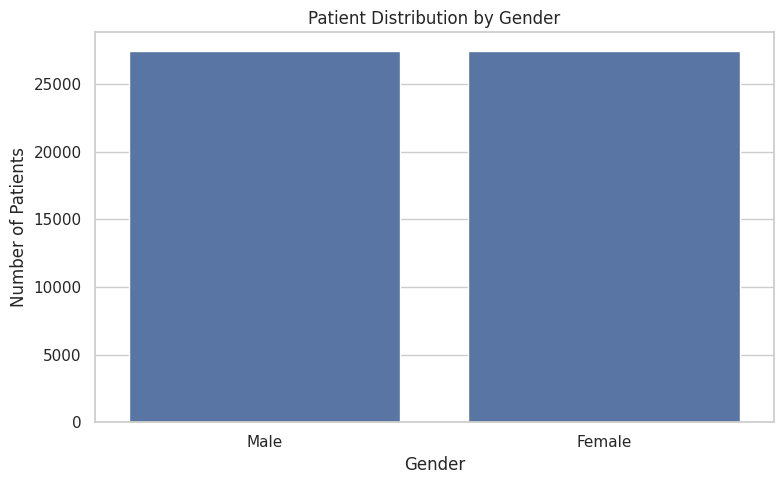

In [53]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="Gender"
)

plt.title("Patient Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

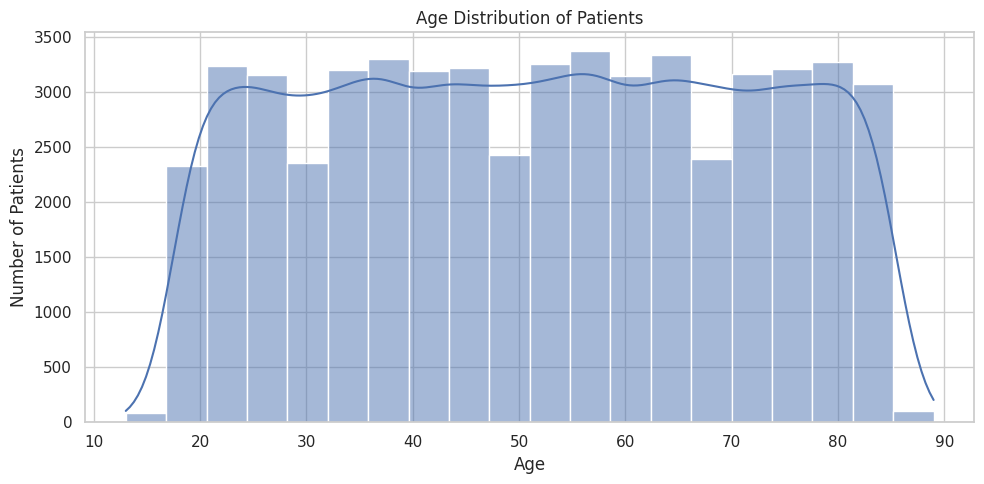

In [54]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data["Age"],
    bins=20,
    kde=True
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

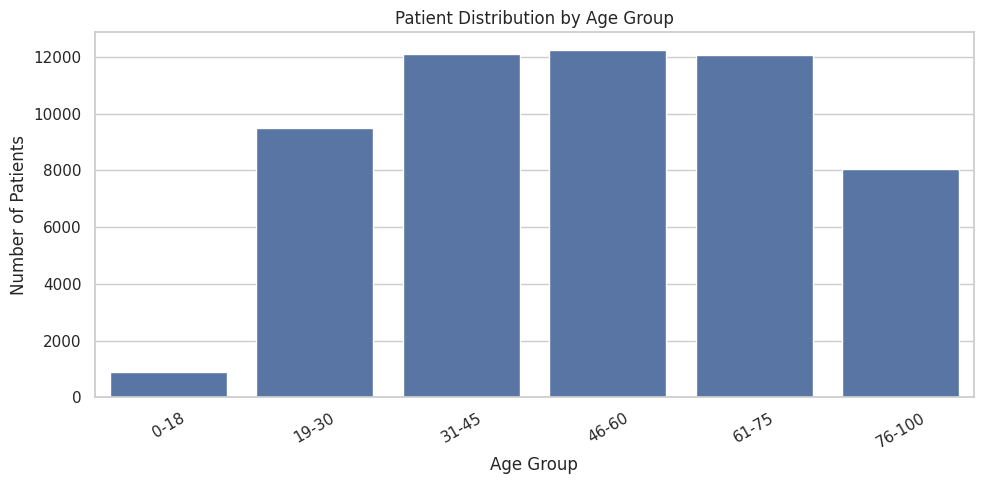

In [55]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=data,
    x="Age Group"
)

plt.title("Patient Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

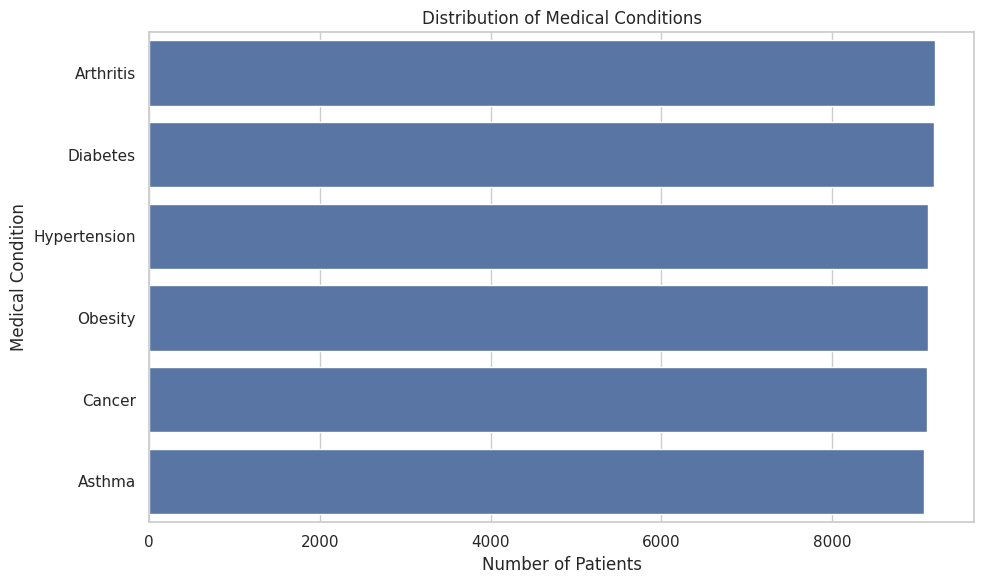

In [56]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    y="Medical Condition",
    order=data["Medical Condition"].value_counts().index
)

plt.title("Distribution of Medical Conditions")
plt.xlabel("Number of Patients")
plt.ylabel("Medical Condition")
plt.tight_layout()
plt.show()

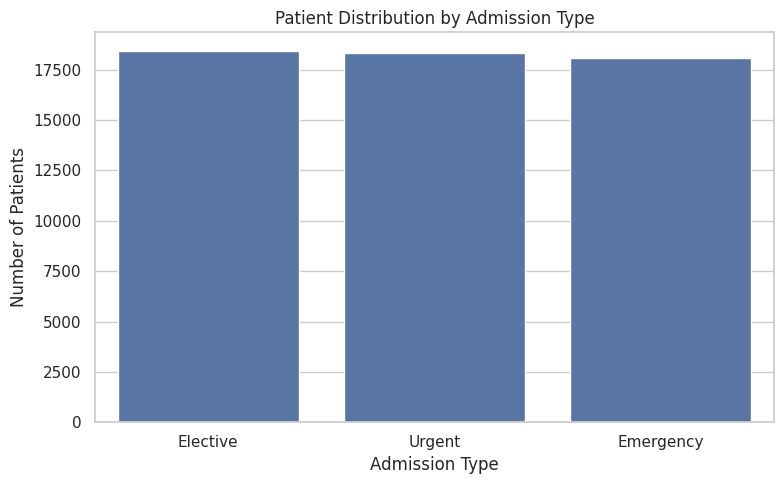

In [57]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="Admission Type",
    order=data["Admission Type"].value_counts().index
)

plt.title("Patient Distribution by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

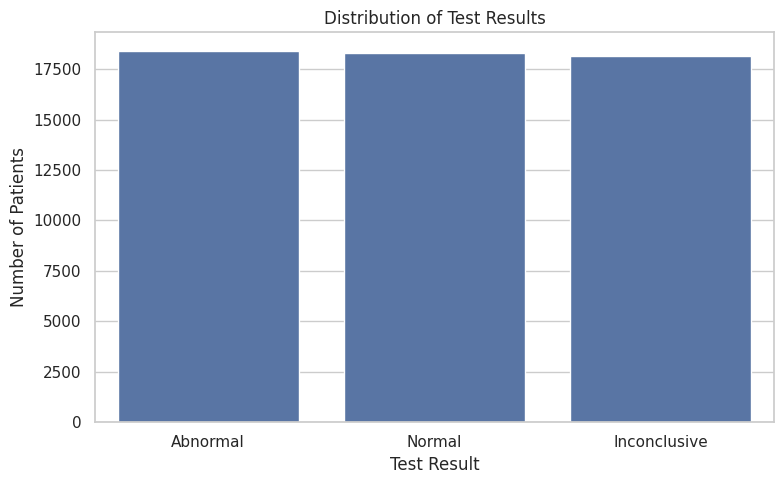

In [58]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="Test Results",
    order=data["Test Results"].value_counts().index
)

plt.title("Distribution of Test Results")
plt.xlabel("Test Result")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

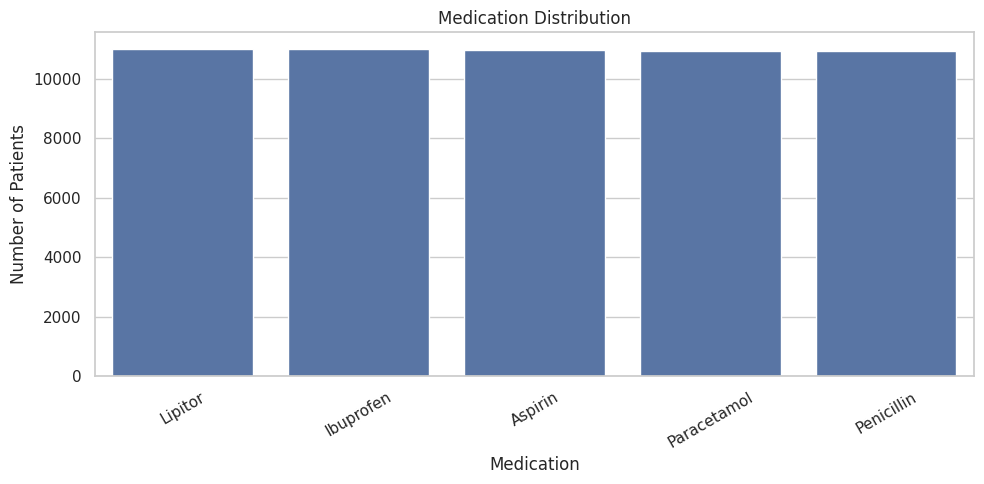

In [59]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=data,
    x="Medication",
    order=data["Medication"].value_counts().index
)

plt.title("Medication Distribution")
plt.xlabel("Medication")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

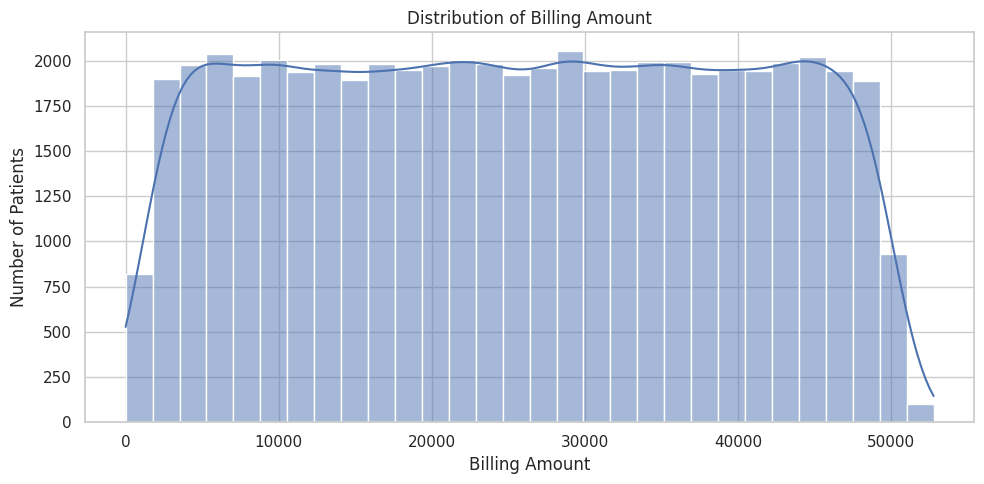

In [60]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data["Billing Amount"],
    bins=30,
    kde=True
)

plt.title("Distribution of Billing Amount")
plt.xlabel("Billing Amount")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

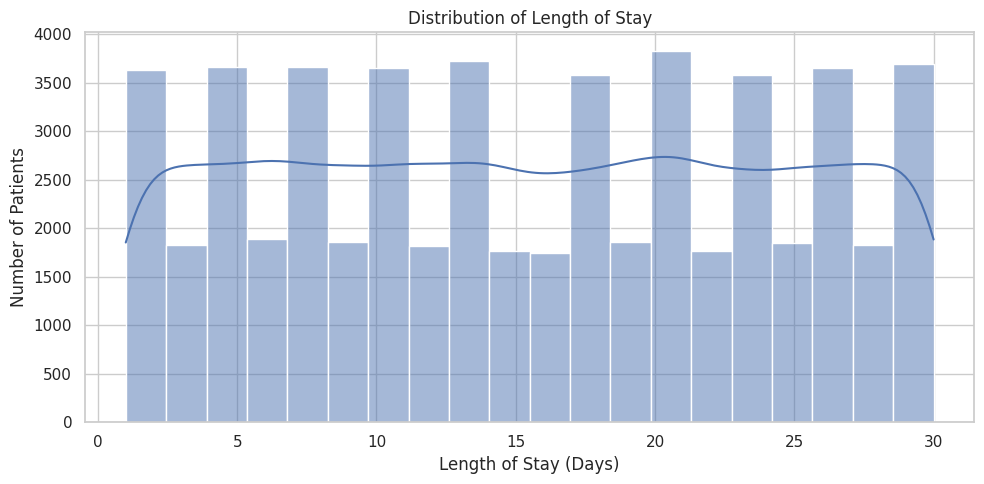

In [61]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data["Length of Stay"],
    bins=20,
    kde=True
)

plt.title("Distribution of Length of Stay")
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

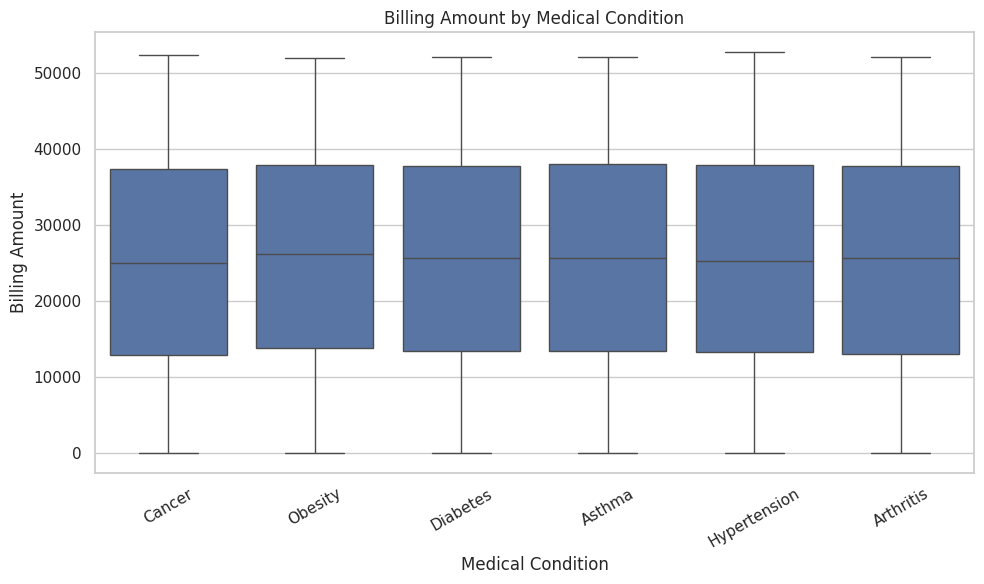

In [62]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x="Medical Condition",
    y="Billing Amount"
)

plt.title("Billing Amount by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Billing Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

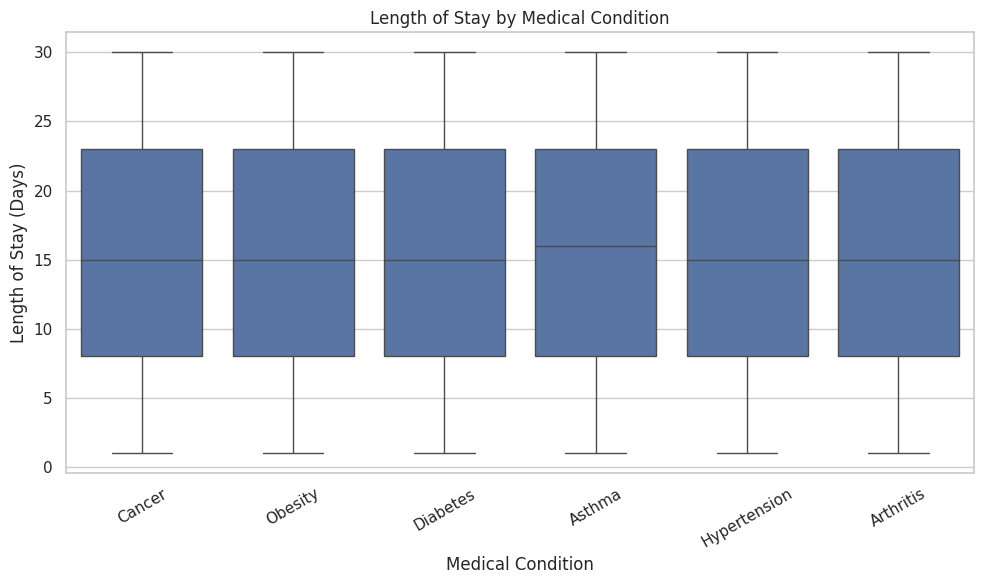

In [63]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x="Medical Condition",
    y="Length of Stay"
)

plt.title("Length of Stay by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Length of Stay (Days)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

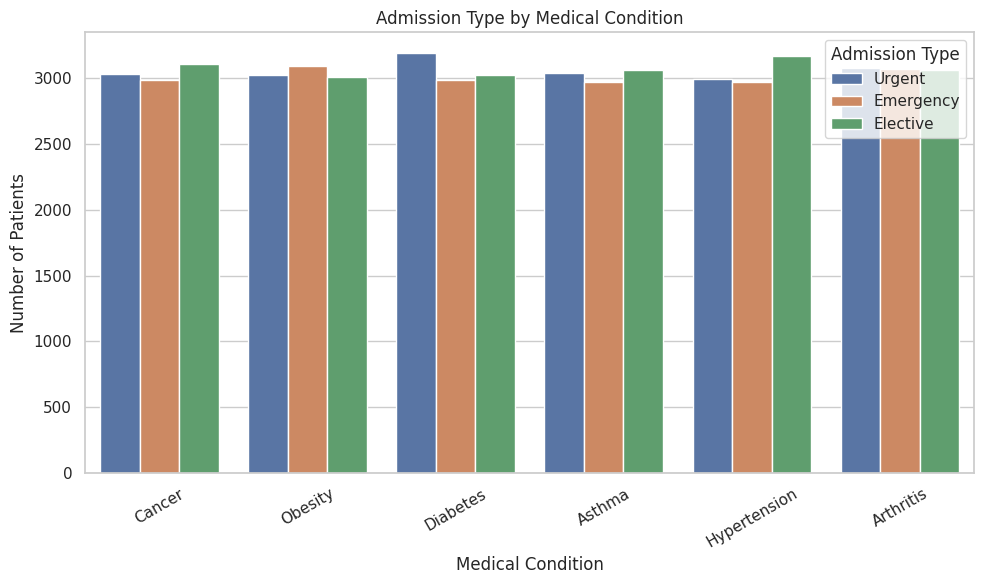

In [64]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x="Medical Condition",
    hue="Admission Type"
)

plt.title("Admission Type by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

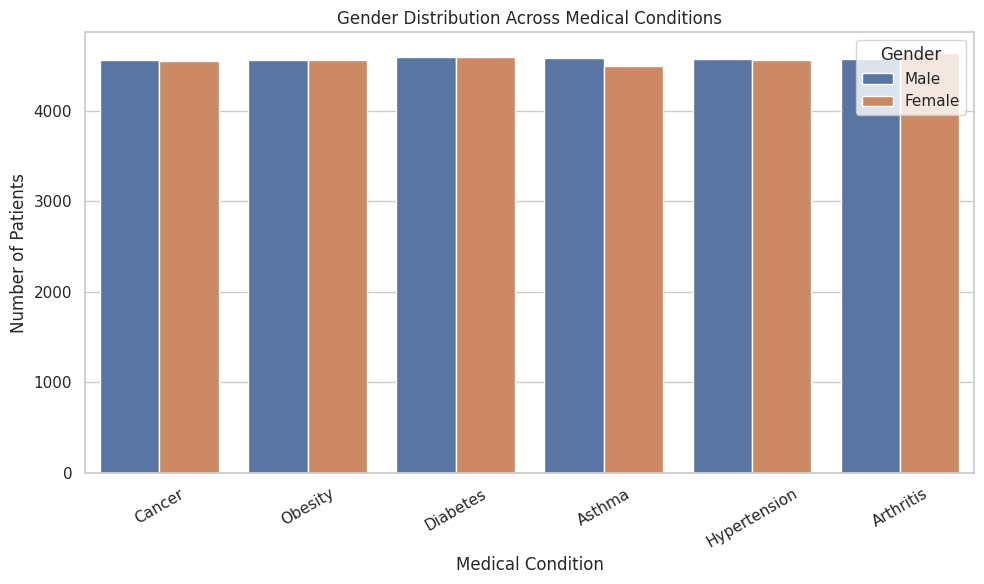

In [65]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x="Medical Condition",
    hue="Gender"
)

plt.title("Gender Distribution Across Medical Conditions")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

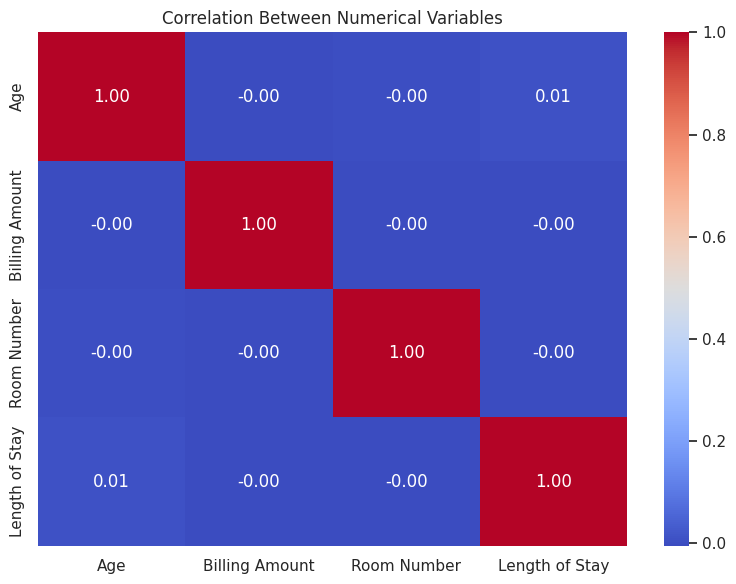

In [66]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

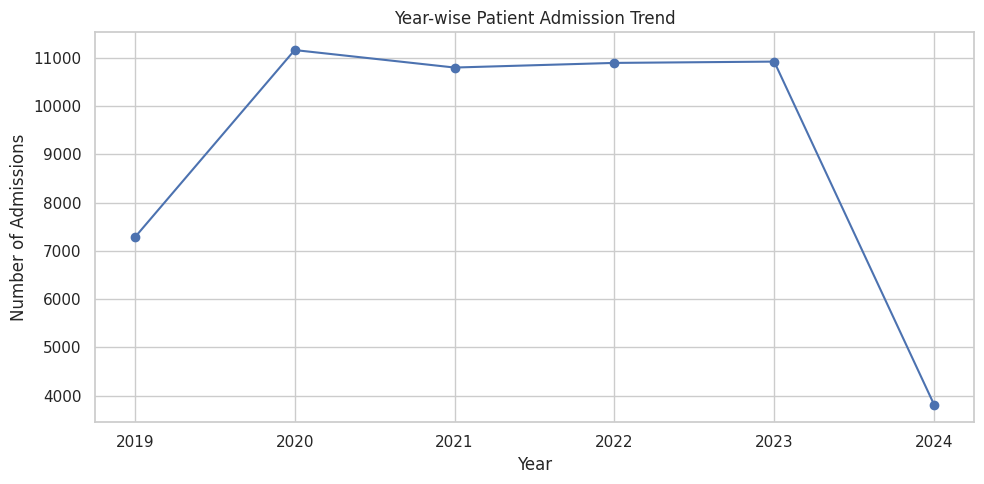

In [67]:
plt.figure(figsize=(10, 5))

yearly_admissions.plot(
    kind="line",
    marker="o"
)

plt.title("Year-wise Patient Admission Trend")
plt.xlabel("Year")
plt.ylabel("Number of Admissions")
plt.grid(True)
plt.tight_layout()
plt.show()

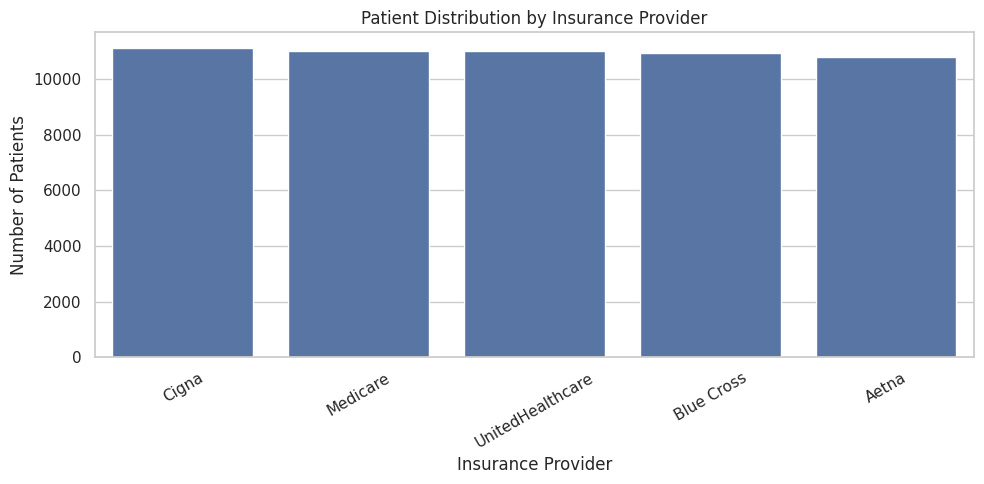

In [68]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=data,
    x="Insurance Provider",
    order=data["Insurance Provider"].value_counts().index
)

plt.title("Patient Distribution by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [69]:
print("\n")
print("=" * 70)
print("       HOSPITAL PATIENT DATA ANALYSIS - KEY INSIGHTS")
print("=" * 70)

# Basic statistics
print("\n1. DATASET SUMMARY")
print("-" * 50)

print("Total patient records:", len(data))
print("Number of attributes:", len(data.columns))

# Age
print("\n2. PATIENT AGE")
print("-" * 50)

print("Average patient age:",
      round(data["Age"].mean(), 2))

print("Minimum patient age:",
      data["Age"].min())

print("Maximum patient age:",
      data["Age"].max())

# Gender
print("\n3. GENDER")
print("-" * 50)

gender_counts = data["Gender"].value_counts()

print("Most common gender:",
      gender_counts.idxmax())

print("Number of patients:",
      gender_counts.max())

# Medical condition
print("\n4. MEDICAL CONDITIONS")
print("-" * 50)

condition_counts = data["Medical Condition"].value_counts()

print("Most common medical condition:",
      condition_counts.idxmax())

print("Number of patients:",
      condition_counts.max())

# Admission
print("\n5. ADMISSION TYPE")
print("-" * 50)

admission_counts = data["Admission Type"].value_counts()

print("Most common admission type:",
      admission_counts.idxmax())

print("Number of admissions:",
      admission_counts.max())

# Test results
print("\n6. TEST RESULTS")
print("-" * 50)

test_counts = data["Test Results"].value_counts()

print("Most common test result:",
      test_counts.idxmax())

# Medication
print("\n7. MEDICATION")
print("-" * 50)

medication_counts = data["Medication"].value_counts()

print("Most common medication:",
      medication_counts.idxmax())

# Insurance
print("\n8. INSURANCE PROVIDER")
print("-" * 50)

insurance_counts = data["Insurance Provider"].value_counts()

print("Most common insurance provider:",
      insurance_counts.idxmax())

# Length of stay
print("\n9. LENGTH OF STAY")
print("-" * 50)

print("Average length of stay:",
      round(data["Length of Stay"].mean(), 2), "days")

print("Minimum length of stay:",
      data["Length of Stay"].min(), "days")

print("Maximum length of stay:",
      data["Length of Stay"].max(), "days")

# Billing
print("\n10. BILLING")
print("-" * 50)

print("Average billing amount:",
      round(data["Billing Amount"].mean(), 2))

print("Minimum billing amount:",
      round(data["Billing Amount"].min(), 2))

print("Maximum billing amount:",
      round(data["Billing Amount"].max(), 2))

# Highest average billing condition
highest_billing_condition = (
    data.groupby("Medical Condition")["Billing Amount"]
    .mean()
    .idxmax()
)

highest_billing_value = (
    data.groupby("Medical Condition")["Billing Amount"]
    .mean()
    .max()
)

print("\n11. CONDITION WITH HIGHEST AVERAGE BILLING")
print("-" * 50)

print("Medical condition:",
      highest_billing_condition)

print("Average billing:",
      round(highest_billing_value, 2))

# Longest average stay condition
longest_stay_condition = (
    data.groupby("Medical Condition")["Length of Stay"]
    .mean()
    .idxmax()
)

longest_stay_value = (
    data.groupby("Medical Condition")["Length of Stay"]
    .mean()
    .max()
)

print("\n12. CONDITION WITH LONGEST AVERAGE STAY")
print("-" * 50)

print("Medical condition:",
      longest_stay_condition)

print("Average length of stay:",
      round(longest_stay_value, 2), "days")

print("\n")
print("=" * 70)
print("             ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 70)



       HOSPITAL PATIENT DATA ANALYSIS - KEY INSIGHTS

1. DATASET SUMMARY
--------------------------------------------------
Total patient records: 54860
Number of attributes: 19

2. PATIENT AGE
--------------------------------------------------
Average patient age: 51.53
Minimum patient age: 13
Maximum patient age: 89

3. GENDER
--------------------------------------------------
Most common gender: Male
Number of patients: 27449

4. MEDICAL CONDITIONS
--------------------------------------------------
Most common medical condition: Arthritis
Number of patients: 9207

5. ADMISSION TYPE
--------------------------------------------------
Most common admission type: Elective
Number of admissions: 18437

6. TEST RESULTS
--------------------------------------------------
Most common test result: Abnormal

7. MEDICATION
--------------------------------------------------
Most common medication: Lipitor

8. INSURANCE PROVIDER
--------------------------------------------------
Most common insu